# Equidade das predicoes de obito entre subgrupos demograficos, teste de 2024

Este notebook avalia se a capacidade dos cinco algoritmos de discriminar o risco de obito por chikungunya varia entre subgrupos demograficos do teste de 2024.
As variaveis de estratificacao sao sexo, raca ou cor, e faixa etaria, as tres colunas demograficas usadas aqui a partir de `data/features/baseline/X_test.parquet`.
Para cada subgrupo e cada um dos cinco algoritmos ja treinados na fase de modelagem, a AUPRC e o ROC-AUC sao recalculados apenas sobre os casos daquele subgrupo, a partir das probabilidades preditas ja salvas em `output/metricas/`.
A diferenca entre a metrica de um subgrupo e a do subgrupo de referencia da mesma variavel, chamada aqui de delta AUPRC e delta ROC-AUC, e a medida central usada para comparar a equidade do desempenho do modelo entre subgrupos.
Delta AUPRC e delta ROC-AUC, com intervalo de confianca de 95 por cento por bootstrap de duas amostras independentes, sao calculados para todos os subgrupos de todas as variaveis, sem nenhum pre-filtro por numero de obitos.
A decisao de quais subgrupos entram na comparacao de disparidade e de significancia estatistica usa um criterio separado, baseado na largura do intervalo de confianca de 95 por cento da propria ROC-AUC do subgrupo, exigida abaixo de uma largura-alvo nos cinco algoritmos ao mesmo tempo, detalhado na secao de incerteza amostral mais adiante.
Este notebook reporta apenas os numeros observados nos cinco algoritmos sobre o teste de 2024, sem nenhuma comparacao com valores de referencia externos a este estudo.

Importa as bibliotecas necessarias, define os diretorios de entrada e saida, e fixa a lista dos cinco algoritmos avaliados ao longo do notebook.
As tabelas de metricas por subgrupo sao salvas em `analysis/results_equidade/`, e os graficos de delta AUPRC sao salvos em `analysis/plots/equidade/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd().parent.parent
DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_equidade"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "equidade"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
METRICA_INDEFINIDA = "metrica indefinida: subgrupo com uma unica classe de desfecho"

Carrega as tres colunas demograficas do teste de 2024 a partir de `data/features/baseline/X_test.parquet`: sexo, raca ou cor, e idade em anos.
A idade em anos e convertida em cinco faixas etarias fixas, menor que 1 ano, de 1 a 17 anos, de 18 a 39 anos, de 40 a 59 anos, e 60 anos ou mais, a terceira variavel de estratificacao usada neste notebook.
Um caso sem idade registrada fica sem faixa etaria definida e e naturalmente excluido das tabelas por faixa etaria mais adiante, da mesma forma que os dois casos com sexo igual a "I", ignorado, sao excluidos da comparacao por sexo por serem uma amostra irrelevante.

In [2]:
COLUNAS_DEMOGRAFICAS = ["CS_SEXO", "CS_RACA", "IDADE_ANOS"]
LIMITES_FAIXA_ETARIA = [0, 1, 18, 40, 60, 105]
ROTULOS_FAIXA_ETARIA = ["<1", "1-17", "18-39", "40-59", "60+"]

covariaveis_teste2024 = pd.read_parquet(
    DIRETORIO_FEATURES / "X_test.parquet", columns=COLUNAS_DEMOGRAFICAS
).reset_index(drop=True)
covariaveis_teste2024["faixa_etaria"] = pd.cut(
    covariaveis_teste2024["IDADE_ANOS"],
    bins=LIMITES_FAIXA_ETARIA,
    labels=ROTULOS_FAIXA_ETARIA,
    right=False,
)

numero_registros_sem_faixa_etaria = covariaveis_teste2024["faixa_etaria"].isna().sum()
covariaveis_teste2024.shape, numero_registros_sem_faixa_etaria

((3978, 4), np.int64(1))

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real de obito ja salvos pela fase de modelagem para o teste de 2024.
Confirma que o alvo real e identico entre os cinco arquivos e que o numero de registros coincide com o das colunas demograficas carregadas na celula anterior, ja que ambos vem do mesmo conjunto de teste na mesma ordem posicional.
Concatena, para cada algoritmo, a tabela de predicoes com as colunas demograficas pela posicao da linha, criando uma unica tabela por algoritmo usada no restante do notebook.

In [3]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet"
    ).reset_index(drop=True)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis = len(covariaveis_teste2024)
alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
for algoritmo in ALGORITMOS:
    assert len(predicoes_teste2024[algoritmo]) == numero_registros_covariaveis
    assert np.array_equal(predicoes_teste2024[algoritmo]["obito"].to_numpy(), alvo_real_teste2024)

predicoes_com_covariaveis = {
    algoritmo: pd.concat([predicoes_teste2024[algoritmo], covariaveis_teste2024], axis=1)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis, int(alvo_real_teste2024.sum())

(3978, 208)

Define as tres variaveis de estratificacao analisadas neste notebook, sexo, raca ou cor, e faixa etaria, cada uma com seus subgrupos validos, os rotulos legiveis de cada subgrupo, e o subgrupo de referencia usado no calculo do delta.
O subgrupo de referencia e feminino para sexo, branca para raca ou cor, e a faixa de 18 a 39 anos para faixa etaria, a faixa com a menor prevalencia observada de obito entre as faixas etarias elegiveis para comparacao pelo criterio de estabilidade estatistica definido na secao de incerteza amostral mais adiante neste notebook.
O codigo 9 de raca ou cor, rotulado ignorado, nao representa uma categoria racial, e qualquer diferenca de desempenho associada a ele deve ser lida como uma limitacao de qualidade do registro do dado, e nao como evidencia de equidade racial, ainda que receba o mesmo tratamento quantitativo dos demais subgrupos nesta analise.

In [4]:
ROTULOS_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indigena",
    "9": "Ignorado",
}

ESPECIFICACOES_ESTRATIFICACAO = [
    {
        "variavel_estratificacao": "sexo",
        "rotulo_variavel": "sexo",
        "coluna": "CS_SEXO",
        "subgrupos": ["F", "M"],
        "rotulos_subgrupo": {"F": "Feminino", "M": "Masculino"},
        "subgrupo_referencia": "F",
    },
    {
        "variavel_estratificacao": "raca_cor",
        "rotulo_variavel": "raca ou cor",
        "coluna": "CS_RACA",
        "subgrupos": ["1", "2", "3", "4", "5", "9"],
        "rotulos_subgrupo": ROTULOS_RACA_COR,
        "subgrupo_referencia": "1",
    },
    {
        "variavel_estratificacao": "faixa_etaria",
        "rotulo_variavel": "faixa etaria",
        "coluna": "faixa_etaria",
        "subgrupos": ROTULOS_FAIXA_ETARIA,
        "rotulos_subgrupo": {rotulo: rotulo for rotulo in ROTULOS_FAIXA_ETARIA},
        "subgrupo_referencia": "18-39",
    },
]

[especificacao["variavel_estratificacao"] for especificacao in ESPECIFICACOES_ESTRATIFICACAO]

['sexo', 'raca_cor', 'faixa_etaria']

Para cada variavel de estratificacao, cada algoritmo e cada subgrupo, calcula o numero de casos, o numero de obitos, a prevalencia observada de obito, a AUPRC e o ROC-AUC restritos aos casos daquele subgrupo, sem nenhum pre-filtro por numero de obitos.
A AUPRC e o ROC-AUC sao calculados com `average_precision_score` e `roc_auc_score` do scikit-learn, sobre a probabilidade predita e o desfecho real daquele algoritmo, apenas nas linhas do subgrupo em questao.
Um subgrupo em que todos os casos compartilham o mesmo desfecho, isto e, zero obitos ou obito em cem por cento dos casos, recebe o texto de metrica indefinida nessas colunas, porque a AUPRC e o ROC-AUC exigem matematicamente pelo menos um caso de cada classe para serem calculados, o que nao depende de nenhuma escolha metodologica.
A estabilidade da estimativa de cada subgrupo, incluindo os que tem poucos obitos mas ainda assim as duas classes presentes, e avaliada mais adiante neste notebook pela largura do intervalo de confianca de 95 por cento da ROC-AUC obtido por bootstrap, e nao por um limiar fixo de numero de eventos.

In [5]:
linhas_metricas_subgrupo = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        for subgrupo in especificacao["subgrupos"]:
            tabela_filtrada = tabela_algoritmo.loc[tabela_algoritmo[especificacao["coluna"]] == subgrupo]
            numero_registros = len(tabela_filtrada)
            numero_obitos = int(tabela_filtrada["obito"].sum())

            if numero_obitos == 0 or numero_obitos == numero_registros:
                auprc_subgrupo = METRICA_INDEFINIDA
                roc_auc_subgrupo = METRICA_INDEFINIDA
            else:
                auprc_subgrupo = average_precision_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )
                roc_auc_subgrupo = roc_auc_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )

            linhas_metricas_subgrupo.append(
                {
                    "variavel_estratificacao": especificacao["variavel_estratificacao"],
                    "subgrupo": especificacao["rotulos_subgrupo"][subgrupo],
                    "algoritmo": algoritmo,
                    "n": numero_registros,
                    "obitos": numero_obitos,
                    "prevalencia_obito": numero_obitos / numero_registros,
                    "auprc": auprc_subgrupo,
                    "roc_auc": roc_auc_subgrupo,
                }
            )

tabela_metricas_subgrupo = pd.DataFrame(linhas_metricas_subgrupo)
tabela_metricas_subgrupo

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.227969,0.823805
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.209172,0.790043
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106632,0.745982
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.140518,0.691517
4,sexo,Feminino,random_forest,2196,90,0.040984,0.180106,0.822264
5,sexo,Masculino,random_forest,1780,118,0.066292,0.203019,0.780125
6,sexo,Feminino,xgboost,2196,90,0.040984,0.180951,0.776184
7,sexo,Masculino,xgboost,1780,118,0.066292,0.216019,0.746084
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.143,0.74417
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.191617,0.732434


Lista, de forma explicita, os subgrupos em que a AUPRC e o ROC-AUC sao matematicamente indefinidos, por reunirem uma unica classe de desfecho entre os casos observados.
Como essa condicao depende apenas da composicao do subgrupo, e nao do algoritmo, cada combinacao de variavel e subgrupo aparece aqui uma unica vez, mesmo tendo sido calculada para os cinco algoritmos na celula anterior.
Esses subgrupos sao diferentes dos subgrupos apenas instaveis, tratados mais adiante pelo criterio de largura de intervalo de confianca, porque nenhuma quantidade de reamostragem bootstrap resolve a ausencia completa de uma das duas classes de desfecho.

In [6]:
subgrupos_metrica_indefinida = (
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["auprc"].apply(lambda valor: isinstance(valor, str)),
        ["variavel_estratificacao", "subgrupo", "obitos"],
    ]
    .drop_duplicates()
    .sort_values(["variavel_estratificacao", "obitos"])
    .reset_index(drop=True)
)
subgrupos_metrica_indefinida

,variavel_estratificacao,subgrupo,obitos
0,raca_cor,Indigena,0


Salva a tabela de metricas por subgrupo em tres arquivos separados, um por variavel de estratificacao, em `analysis/results_equidade/`, para facilitar a leitura isolada de cada variavel.

In [7]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel
    ].to_csv(DIRETORIO_RESULTADOS_ANALISE / f"metricas_por_subgrupo_{nome_variavel}.csv", index=False)

sorted(caminho.name for caminho in DIRETORIO_RESULTADOS_ANALISE.glob("metricas_por_subgrupo_*.csv"))

['metricas_por_subgrupo_faixa_etaria.csv',
 'metricas_por_subgrupo_raca_cor.csv',
 'metricas_por_subgrupo_sexo.csv']

Para cada variavel de estratificacao e cada algoritmo, calcula o delta AUPRC e o delta ROC-AUC de cada subgrupo em relacao ao subgrupo de referencia daquela variavel, subtraindo a metrica do subgrupo de referencia da metrica do subgrupo em questao.
Quando a metrica do subgrupo, a do subgrupo de referencia, ou as duas, e matematicamente indefinida por uma unica classe de desfecho, o delta correspondente tambem e marcado como indefinido, em vez de um valor numerico.
O subgrupo de referencia de cada variavel aparece na tabela final com delta igual a zero, por definicao, servindo de linha de base nos graficos da secao seguinte.

In [8]:
referencias_por_variavel_algoritmo = {}
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    rotulo_referencia = especificacao["rotulos_subgrupo"][especificacao["subgrupo_referencia"]]
    linhas_referencia = tabela_metricas_subgrupo.loc[
        (tabela_metricas_subgrupo["variavel_estratificacao"] == especificacao["variavel_estratificacao"])
        & (tabela_metricas_subgrupo["subgrupo"] == rotulo_referencia)
    ]
    for _, linha_referencia in linhas_referencia.iterrows():
        chave_variavel_algoritmo = (linha_referencia["variavel_estratificacao"], linha_referencia["algoritmo"])
        referencias_por_variavel_algoritmo[chave_variavel_algoritmo] = (
            linha_referencia["auprc"],
            linha_referencia["roc_auc"],
        )


def calcular_delta_metrica(valor_subgrupo, valor_referencia):
    if isinstance(valor_subgrupo, str) or isinstance(valor_referencia, str):
        return METRICA_INDEFINIDA
    return valor_subgrupo - valor_referencia


linhas_consolidadas = []
for _, linha in tabela_metricas_subgrupo.iterrows():
    auprc_referencia, roc_auc_referencia = referencias_por_variavel_algoritmo[
        (linha["variavel_estratificacao"], linha["algoritmo"])
    ]
    linhas_consolidadas.append(
        {
            "variavel_estratificacao": linha["variavel_estratificacao"],
            "subgrupo": linha["subgrupo"],
            "algoritmo": linha["algoritmo"],
            "n": linha["n"],
            "obitos": linha["obitos"],
            "prevalencia_obito": linha["prevalencia_obito"],
            "auprc": linha["auprc"],
            "roc_auc": linha["roc_auc"],
            "delta_auprc": calcular_delta_metrica(linha["auprc"], auprc_referencia),
            "delta_roc_auc": calcular_delta_metrica(linha["roc_auc"], roc_auc_referencia),
        }
    )

tabela_equidade_consolidada = pd.DataFrame(linhas_consolidadas)
tabela_equidade_consolidada

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.227969,0.823805,0.0,0.0
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.209172,0.790043,-0.018797,-0.033762
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106632,0.745982,0.0,0.0
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.140518,0.691517,0.033886,-0.054466
4,sexo,Feminino,random_forest,2196,90,0.040984,0.180106,0.822264,0.0,0.0
5,sexo,Masculino,random_forest,1780,118,0.066292,0.203019,0.780125,0.022913,-0.042139
6,sexo,Feminino,xgboost,2196,90,0.040984,0.180951,0.776184,0.0,0.0
7,sexo,Masculino,xgboost,1780,118,0.066292,0.216019,0.746084,0.035068,-0.0301
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.143,0.74417,0.0,0.0
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.191617,0.732434,0.048617,-0.011736


Salva a tabela consolidada de metricas e deltas por subgrupo em `analysis/results_equidade/tabela_equidade_consolidada.csv`, reunindo as tres variaveis de estratificacao numa unica tabela longa, com uma linha por combinacao de variavel, subgrupo e algoritmo.

In [9]:
tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)
tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(
    drop=True
)

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,0.012788,0.681647,-0.02053,0.005629
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,0.010861,0.527778,-0.038869,-0.140784
2,faixa_etaria,1-17,random_forest,846,6,0.007092,0.009672,0.552579,-0.035873,-0.18645
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,0.015836,0.699206,-0.097716,-0.076738
4,faixa_etaria,1-17,xgboost,846,6,0.007092,0.009244,0.535317,-0.024467,-0.0559
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.033318,0.676018,0.0,0.0
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.04973,0.668561,0.0,0.0
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.045544,0.739029,0.0,0.0
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.113552,0.775944,0.0,0.0
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.033711,0.591217,0.0,0.0


## Incerteza amostral dos deltas de equidade por bootstrap, e criterio de elegibilidade para a comparacao

Os deltas de AUPRC e de ROC-AUC calculados nas secoes anteriores sao estimativas pontuais, calculadas uma unica vez sobre o teste de 2024, sem nenhuma medida de incerteza associada.
Entre rodadas recentes de retreino dos cinco algoritmos, motivadas por correcoes de features nao relacionadas a equidade, a direcao de varios desses deltas mudou de sinal, o que sugere que parte deles pode ser dominada por ruido amostral em vez de refletir uma diferenca real de desempenho entre subgrupos.
Esta secao estima, para todo subgrupo de toda variavel de estratificacao, sem nenhum pre-filtro por numero de obitos, um intervalo de confianca de 95 por cento por bootstrap, com o objetivo de separar deltas estatisticamente distintos de zero de deltas que podem ser inteiramente explicados por variacao amostral.

Subgrupo e subgrupo de referencia sao populacoes disjuntas de pacientes dentro do mesmo teste de 2024, e nao a mesma populacao medida duas vezes, de forma que o bootstrap usado aqui reamostra os dois grupos de forma independente, com reposicao, em cada iteracao.
Essa escolha segue a mesma convencao de numero de reamostragens e semente aleatoria do notebook de comparacao de algoritmos da fase de avaliacao, mas usa reamostragem de duas amostras independentes em vez de reamostragem pareada, porque os subgrupos aqui comparados, diferente dos algoritmos daquele notebook, nunca compartilham os mesmos pacientes.
Uma iteracao e descartada sempre que a reamostragem do subgrupo ou a reamostragem da referencia, nessa iteracao, nao contiver as duas classes de desfecho, caso em que AUPRC e ROC-AUC deixam de ser definidos.
Um subgrupo cuja amostra original, antes de qualquer reamostragem, ja reune uma unica classe de desfecho nunca passa esse teste em nenhuma iteracao, e o bootstrap e simplesmente pulado para ele, com o delta marcado como indefinido, pelo mesmo motivo matematico da secao anterior.
O subgrupo de referencia de cada variavel nao participa deste bootstrap como alvo de delta, porque compara-lo contra ele mesmo nao testa nenhuma hipotese de equidade, visto que seu delta pontual ja e zero por definicao.

Alem do delta, cada iteracao do bootstrap tambem calcula a ROC-AUC da reamostragem do subgrupo isoladamente e a ROC-AUC da reamostragem da referencia isoladamente, antes de subtrai-las.
Essas duas distribuicoes sao reaproveitadas, sem nenhum bootstrap adicional, para estimar o intervalo de confianca de 95 por cento da ROC-AUC de cada subgrupo isolado, incluindo os subgrupos de referencia.
A largura desse intervalo, limite superior menos limite inferior, e a medida de estabilidade estatistica usada para decidir, mais adiante nesta secao, quais subgrupos entram na comparacao de disparidade entre algoritmos, substituindo o limiar fixo de numero de obitos usado em versoes anteriores desta analise.
A celula seguinte fixa o numero de reamostragens em 2000 e a semente aleatoria em 42, e cria o gerador de numeros aleatorios usado em todo o bootstrap desta secao.

In [10]:
NUMERO_REAMOSTRAGENS = 2000
SEMENTE_ALEATORIA = 42
gerador_aleatorio = np.random.default_rng(SEMENTE_ALEATORIA)

A celula seguinte percorre todas as combinacoes de variavel de estratificacao, subgrupo e algoritmo da tabela consolidada, sem nenhum pre-filtro por numero de obitos, usando as mesmas probabilidades preditas e os mesmos alvos reais ja carregados em `predicoes_com_covariaveis`.
Para cada combinacao em que o subgrupo nao e o subgrupo de referencia e em que tanto o subgrupo quanto a referencia reunem as duas classes de desfecho na amostra original, os indices do subgrupo e os indices da referencia sao reamostrados de forma independente em cada uma das 2000 iteracoes, respeitando o tamanho original de cada um dos dois grupos.
AUPRC e ROC-AUC sao recalculados sobre as duas reamostragens de cada iteracao, a diferenca entre a metrica do subgrupo reamostrado e a da referencia reamostrada forma a distribuicao bootstrap do delta daquela combinacao, e a ROC-AUC isolada de cada lado e guardada, por subgrupo, em `distribuicoes_roc_auc_bootstrap_subgrupo`.
Ao final das 2000 iteracoes, o intervalo de confianca de 95 por cento de cada delta usa os percentis 2,5 e 97,5 da distribuicao de deltas, a fracao de reamostragens com delta positivo mede a direcao da evidencia, e o delta e marcado como significativo apenas quando os dois limites do intervalo tem o mesmo sinal, isto e, quando o intervalo nao contem zero.
Combinacoes em que o subgrupo ou a referencia reunem uma unica classe de desfecho na amostra original sao marcadas como indefinidas sem executar nenhuma reamostragem, por nao haver nenhuma iteracao valida possivel.

In [11]:
distribuicoes_roc_auc_bootstrap_subgrupo = {}
linhas_bootstrap_equidade = []

for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    coluna = especificacao["coluna"]
    codigo_referencia = especificacao["subgrupo_referencia"]
    rotulo_referencia = especificacao["rotulos_subgrupo"][codigo_referencia]

    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        tabela_referencia = tabela_algoritmo.loc[tabela_algoritmo[coluna] == codigo_referencia]
        alvo_referencia = tabela_referencia["obito"].to_numpy()
        probabilidade_referencia = tabela_referencia["probabilidade_predita"].to_numpy()
        numero_registros_referencia = len(alvo_referencia)
        numero_obitos_referencia = int(alvo_referencia.sum())
        referencia_tem_as_duas_classes = 0 < numero_obitos_referencia < numero_registros_referencia
        chave_referencia = (nome_variavel, rotulo_referencia, algoritmo)

        for codigo_subgrupo in especificacao["subgrupos"]:
            rotulo_subgrupo = especificacao["rotulos_subgrupo"][codigo_subgrupo]

            if codigo_subgrupo == codigo_referencia:
                continue

            tabela_subgrupo = tabela_algoritmo.loc[tabela_algoritmo[coluna] == codigo_subgrupo]
            alvo_subgrupo = tabela_subgrupo["obito"].to_numpy()
            probabilidade_subgrupo = tabela_subgrupo["probabilidade_predita"].to_numpy()
            numero_registros_subgrupo = len(alvo_subgrupo)
            numero_obitos_subgrupo = int(alvo_subgrupo.sum())
            subgrupo_tem_as_duas_classes = 0 < numero_obitos_subgrupo < numero_registros_subgrupo
            chave_subgrupo = (nome_variavel, rotulo_subgrupo, algoritmo)

            if not (subgrupo_tem_as_duas_classes and referencia_tem_as_duas_classes):
                linhas_bootstrap_equidade.append(
                    {
                        "variavel_estratificacao": nome_variavel,
                        "subgrupo": rotulo_subgrupo,
                        "algoritmo": algoritmo,
                        "delta_auprc_ic95_inferior": METRICA_INDEFINIDA,
                        "delta_auprc_ic95_superior": METRICA_INDEFINIDA,
                        "delta_auprc_fracao_reamostragens_positivo": METRICA_INDEFINIDA,
                        "delta_auprc_significancia": METRICA_INDEFINIDA,
                        "delta_roc_auc_ic95_inferior": METRICA_INDEFINIDA,
                        "delta_roc_auc_ic95_superior": METRICA_INDEFINIDA,
                        "delta_roc_auc_fracao_reamostragens_positivo": METRICA_INDEFINIDA,
                        "delta_roc_auc_significancia": METRICA_INDEFINIDA,
                        "bootstrap_reamostragens_validas": 0,
                    }
                )
                continue

            deltas_auprc_bootstrap = []
            deltas_roc_auc_bootstrap = []
            roc_auc_subgrupo_bootstrap = []
            roc_auc_referencia_bootstrap = []
            for _ in range(NUMERO_REAMOSTRAGENS):
                indices_subgrupo = gerador_aleatorio.integers(
                    low=0, high=numero_registros_subgrupo, size=numero_registros_subgrupo
                )
                indices_referencia = gerador_aleatorio.integers(
                    low=0, high=numero_registros_referencia, size=numero_registros_referencia
                )

                alvo_subgrupo_reamostrado = alvo_subgrupo[indices_subgrupo]
                alvo_referencia_reamostrado = alvo_referencia[indices_referencia]

                subgrupo_reamostrado_tem_duas_classes = (
                    0 < alvo_subgrupo_reamostrado.sum() < numero_registros_subgrupo
                )
                referencia_reamostrada_tem_duas_classes = (
                    0 < alvo_referencia_reamostrado.sum() < numero_registros_referencia
                )
                if not (subgrupo_reamostrado_tem_duas_classes and referencia_reamostrada_tem_duas_classes):
                    continue

                probabilidade_subgrupo_reamostrada = probabilidade_subgrupo[indices_subgrupo]
                probabilidade_referencia_reamostrada = probabilidade_referencia[indices_referencia]

                auprc_subgrupo_reamostrado = average_precision_score(
                    alvo_subgrupo_reamostrado, probabilidade_subgrupo_reamostrada
                )
                auprc_referencia_reamostrada = average_precision_score(
                    alvo_referencia_reamostrado, probabilidade_referencia_reamostrada
                )
                roc_auc_subgrupo_reamostrado = roc_auc_score(
                    alvo_subgrupo_reamostrado, probabilidade_subgrupo_reamostrada
                )
                roc_auc_referencia_reamostrado = roc_auc_score(
                    alvo_referencia_reamostrado, probabilidade_referencia_reamostrada
                )

                deltas_auprc_bootstrap.append(auprc_subgrupo_reamostrado - auprc_referencia_reamostrada)
                deltas_roc_auc_bootstrap.append(roc_auc_subgrupo_reamostrado - roc_auc_referencia_reamostrado)
                roc_auc_subgrupo_bootstrap.append(roc_auc_subgrupo_reamostrado)
                roc_auc_referencia_bootstrap.append(roc_auc_referencia_reamostrado)

            deltas_auprc_bootstrap = np.array(deltas_auprc_bootstrap)
            deltas_roc_auc_bootstrap = np.array(deltas_roc_auc_bootstrap)
            roc_auc_subgrupo_bootstrap = np.array(roc_auc_subgrupo_bootstrap)
            roc_auc_referencia_bootstrap = np.array(roc_auc_referencia_bootstrap)

            if chave_subgrupo not in distribuicoes_roc_auc_bootstrap_subgrupo:
                distribuicoes_roc_auc_bootstrap_subgrupo[chave_subgrupo] = roc_auc_subgrupo_bootstrap
            if chave_referencia not in distribuicoes_roc_auc_bootstrap_subgrupo:
                distribuicoes_roc_auc_bootstrap_subgrupo[chave_referencia] = roc_auc_referencia_bootstrap

            limite_inferior_auprc = np.percentile(deltas_auprc_bootstrap, 2.5)
            limite_superior_auprc = np.percentile(deltas_auprc_bootstrap, 97.5)
            fracao_positiva_auprc = (deltas_auprc_bootstrap > 0).mean()
            significancia_auprc = (
                "significativo"
                if limite_inferior_auprc * limite_superior_auprc > 0
                else "nao distinguivel de zero amostralmente"
            )

            limite_inferior_roc_auc = np.percentile(deltas_roc_auc_bootstrap, 2.5)
            limite_superior_roc_auc = np.percentile(deltas_roc_auc_bootstrap, 97.5)
            fracao_positiva_roc_auc = (deltas_roc_auc_bootstrap > 0).mean()
            significancia_roc_auc = (
                "significativo"
                if limite_inferior_roc_auc * limite_superior_roc_auc > 0
                else "nao distinguivel de zero amostralmente"
            )

            linhas_bootstrap_equidade.append(
                {
                    "variavel_estratificacao": nome_variavel,
                    "subgrupo": rotulo_subgrupo,
                    "algoritmo": algoritmo,
                    "delta_auprc_ic95_inferior": limite_inferior_auprc,
                    "delta_auprc_ic95_superior": limite_superior_auprc,
                    "delta_auprc_fracao_reamostragens_positivo": fracao_positiva_auprc,
                    "delta_auprc_significancia": significancia_auprc,
                    "delta_roc_auc_ic95_inferior": limite_inferior_roc_auc,
                    "delta_roc_auc_ic95_superior": limite_superior_roc_auc,
                    "delta_roc_auc_fracao_reamostragens_positivo": fracao_positiva_roc_auc,
                    "delta_roc_auc_significancia": significancia_roc_auc,
                    "bootstrap_reamostragens_validas": len(deltas_auprc_bootstrap),
                }
            )

tabela_bootstrap_equidade = pd.DataFrame(linhas_bootstrap_equidade)
tabela_bootstrap_equidade

,variavel_estratificacao,subgrupo,algoritmo,delta_auprc_ic95_inferior,delta_auprc_ic95_superior,delta_auprc_fracao_reamostragens_positivo,delta_auprc_significancia,delta_roc_auc_ic95_inferior,delta_roc_auc_ic95_superior,delta_roc_auc_fracao_reamostragens_positivo,delta_roc_auc_significancia,bootstrap_reamostragens_validas
0,sexo,Masculino,regressao_logistica,-0.126568,0.08053,0.371,nao distinguivel de zero amostralmente,-0.094225,0.025527,0.1325,nao distinguivel de zero amostralmente,2000
1,sexo,Masculino,arvore_decisao,-0.020797,0.079721,0.8945,nao distinguivel de zero amostralmente,-0.133988,0.028098,0.092,nao distinguivel de zero amostralmente,2000
2,sexo,Masculino,random_forest,-0.065626,0.11363,0.7065,nao distinguivel de zero amostralmente,-0.102345,0.01798,0.092,nao distinguivel de zero amostralmente,2000
3,sexo,Masculino,xgboost,-0.072964,0.129477,0.72,nao distinguivel de zero amostralmente,-0.104,0.041023,0.205,nao distinguivel de zero amostralmente,2000
4,sexo,Masculino,lightgbm,-0.039803,0.129414,0.8635,nao distinguivel de zero amostralmente,-0.08599,0.059476,0.367,nao distinguivel de zero amostralmente,2000
5,raca_cor,Preta,regressao_logistica,-0.190661,0.49738,0.675201,nao distinguivel de zero amostralmente,-0.096574,0.190084,0.809237,nao distinguivel de zero amostralmente,1992
6,raca_cor,Amarela,regressao_logistica,-0.214794,0.284468,0.308698,nao distinguivel de zero amostralmente,-0.451815,0.162657,0.285958,nao distinguivel de zero amostralmente,1759
7,raca_cor,Parda,regressao_logistica,-0.082352,0.116635,0.6705,nao distinguivel de zero amostralmente,-0.02237,0.097616,0.8805,nao distinguivel de zero amostralmente,2000
8,raca_cor,Indigena,regressao_logistica,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,metrica indefinida: subgrupo com uma unica cla...,0
9,raca_cor,Ignorado,regressao_logistica,-0.254164,-0.049163,0.004002,significativo,-0.317911,0.060396,0.098049,nao distinguivel de zero amostralmente,1999


Para cada subgrupo e cada algoritmo, inclusive os subgrupos de referencia, esta celula reaproveita a distribuicao bootstrap da ROC-AUC isolada guardada em `distribuicoes_roc_auc_bootstrap_subgrupo` para estimar o intervalo de confianca de 95 por cento da propria ROC-AUC daquele subgrupo, sem executar nenhum bootstrap adicional.
A largura do intervalo, limite superior menos limite inferior, e calculada para cada combinacao de variavel, subgrupo e algoritmo, e sera a base do criterio de elegibilidade para a comparacao de disparidade definido nas celulas seguintes.
Subgrupos sem distribuicao disponivel, por reunirem uma unica classe de desfecho na amostra original, recebem intervalo e largura ausentes, em vez de um numero.
A tabela resultante e ordenada pelo numero de obitos do subgrupo, para deixar visivel a relacao entre numero de obitos e largura do intervalo de confianca, e e salva em `analysis/results_equidade/largura_ic_roc_auc_por_subgrupo.csv`.

In [12]:
linhas_largura_ic_roc_auc = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    for algoritmo in ALGORITMOS:
        for codigo_subgrupo in especificacao["subgrupos"]:
            rotulo_subgrupo = especificacao["rotulos_subgrupo"][codigo_subgrupo]
            linha_metrica = tabela_metricas_subgrupo.loc[
                (tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel)
                & (tabela_metricas_subgrupo["subgrupo"] == rotulo_subgrupo)
                & (tabela_metricas_subgrupo["algoritmo"] == algoritmo)
            ].iloc[0]

            distribuicao_bootstrap = distribuicoes_roc_auc_bootstrap_subgrupo.get(
                (nome_variavel, rotulo_subgrupo, algoritmo)
            )
            if distribuicao_bootstrap is None or len(distribuicao_bootstrap) == 0:
                roc_auc_ic95_inferior = np.nan
                roc_auc_ic95_superior = np.nan
                largura_ic_roc_auc = np.nan
            else:
                roc_auc_ic95_inferior = np.percentile(distribuicao_bootstrap, 2.5)
                roc_auc_ic95_superior = np.percentile(distribuicao_bootstrap, 97.5)
                largura_ic_roc_auc = roc_auc_ic95_superior - roc_auc_ic95_inferior

            linhas_largura_ic_roc_auc.append(
                {
                    "variavel_estratificacao": nome_variavel,
                    "subgrupo": rotulo_subgrupo,
                    "algoritmo": algoritmo,
                    "n": int(linha_metrica["n"]),
                    "obitos": int(linha_metrica["obitos"]),
                    "roc_auc": linha_metrica["roc_auc"],
                    "roc_auc_ic95_inferior": roc_auc_ic95_inferior,
                    "roc_auc_ic95_superior": roc_auc_ic95_superior,
                    "largura_ic_roc_auc": largura_ic_roc_auc,
                }
            )

tabela_largura_ic_roc_auc_subgrupo = pd.DataFrame(linhas_largura_ic_roc_auc).sort_values(
    ["obitos", "variavel_estratificacao", "subgrupo", "algoritmo"]
).reset_index(drop=True)

tabela_largura_ic_roc_auc_subgrupo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "largura_ic_roc_auc_por_subgrupo.csv", index=False
)

tabela_largura_ic_roc_auc_subgrupo

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,roc_auc,roc_auc_ic95_inferior,roc_auc_ic95_superior,largura_ic_roc_auc
0,raca_cor,Indigena,arvore_decisao,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
1,raca_cor,Indigena,lightgbm,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
2,raca_cor,Indigena,random_forest,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
3,raca_cor,Indigena,regressao_logistica,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
4,raca_cor,Indigena,xgboost,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
5,raca_cor,Amarela,arvore_decisao,42,2,0.31875,0.000000,0.719512,0.719512
6,raca_cor,Amarela,lightgbm,42,2,0.775,0.585366,0.926829,0.341463
7,raca_cor,Amarela,random_forest,42,2,0.5125,0.170732,0.853659,0.682927
8,raca_cor,Amarela,regressao_logistica,42,2,0.6625,0.332917,0.950000,0.617083
9,raca_cor,Amarela,xgboost,42,2,0.425,0.243902,0.609756,0.365854


Antes de fixar a largura-alvo usada no restante do notebook, esta celula testa quatro larguras candidatas sobre a tabela real de larguras de intervalo de confianca da celula anterior, para apoiar a escolha final.
Para cada largura candidata, um subgrupo e considerado elegivel quando a maior largura de intervalo de confianca de ROC-AUC entre os cinco algoritmos fica abaixo da largura candidata, a mesma regra de "elegivel nos cinco modelos ao mesmo tempo" usada na analise principal.
A tabela reporta, para cada variavel de estratificacao e cada largura candidata, quantos subgrupos ficam elegiveis, o total de subgrupos daquela variavel, e se o proprio subgrupo de referencia da variavel passa a ser elegivel.
Essa ultima coluna e decisiva, porque uma comparacao de disparidade contra uma referencia nao elegivel nao tem interpretacao estatistica valida, mesmo que outros subgrupos daquela variavel sejam elegiveis isoladamente.
O resultado e salvo em `analysis/results_equidade/sensibilidade_largura_alvo_roc_auc.csv` para referencia futura.

In [13]:
LARGURAS_ALVO_TESTADAS = [0.15, 0.20, 0.35, 0.55]

largura_maxima_por_subgrupo_todas_variaveis = (
    tabela_largura_ic_roc_auc_subgrupo.groupby(["variavel_estratificacao", "subgrupo"])["largura_ic_roc_auc"]
    .max()
    .rename("largura_ic_roc_auc_maxima_entre_modelos")
    .reset_index()
)

linhas_sensibilidade = []
for largura_alvo_testada in LARGURAS_ALVO_TESTADAS:
    avaliacao = largura_maxima_por_subgrupo_todas_variaveis.copy()
    avaliacao["elegivel"] = avaliacao["largura_ic_roc_auc_maxima_entre_modelos"] < largura_alvo_testada

    linha_sensibilidade = {"largura_alvo_roc_auc_testada": largura_alvo_testada}
    for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
        nome_variavel = especificacao["variavel_estratificacao"]
        rotulo_referencia = especificacao["rotulos_subgrupo"][especificacao["subgrupo_referencia"]]
        avaliacao_variavel = avaliacao.loc[avaliacao["variavel_estratificacao"] == nome_variavel]

        linha_sensibilidade[f"{nome_variavel}_elegiveis"] = int(avaliacao_variavel["elegivel"].sum())
        linha_sensibilidade[f"{nome_variavel}_total"] = int(len(avaliacao_variavel))
        referencia_elegivel = avaliacao_variavel.loc[avaliacao_variavel["subgrupo"] == rotulo_referencia, "elegivel"]
        linha_sensibilidade[f"{nome_variavel}_referencia_elegivel"] = bool(referencia_elegivel.iloc[0])

    linhas_sensibilidade.append(linha_sensibilidade)

tabela_sensibilidade_largura_alvo = pd.DataFrame(linhas_sensibilidade)
tabela_sensibilidade_largura_alvo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "sensibilidade_largura_alvo_roc_auc.csv", index=False
)
tabela_sensibilidade_largura_alvo

,largura_alvo_roc_auc_testada,sexo_elegiveis,sexo_total,sexo_referencia_elegivel,raca_cor_elegiveis,raca_cor_total,raca_cor_referencia_elegivel,faixa_etaria_elegiveis,faixa_etaria_total,faixa_etaria_referencia_elegivel
0,0.15,2,2,True,2,6,True,1,5,False
1,0.20,2,2,True,2,6,True,2,5,False
2,0.35,2,2,True,2,6,True,3,5,True
3,0.55,2,2,True,3,6,True,4,5,True


### Escolha da largura-alvo

A tabela real de larguras de intervalo de confianca mostra uma separacao em tres faixas de estabilidade, visivel na coluna `largura_ic_roc_auc_maxima_entre_modelos`.
Um primeiro grupo de cinco subgrupos, 60 anos ou mais, Parda, Feminino, Masculino e Branca, tem a maior largura entre os cinco algoritmos sempre abaixo de 0,13, entre 0,094 e 0,128.
Um segundo grupo, formado por 40 a 59 anos e pela propria referencia de faixa etaria, 18 a 39 anos, tem largura maxima entre 0,19 e 0,31.
Um terceiro grupo de subgrupos pequenos, 1 a 17 anos, Ignorado, Preta, menor que 1 ano e Amarela, tem largura maxima entre 0,52 e 0,72, e Indigena nao tem largura definida por reunir zero obitos.
O maior salto entre subgrupos consecutivos nessa ordenacao acontece exatamente entre o segundo e o terceiro grupo, da largura maxima de 18 a 39 anos, 0,306, para a largura maxima de 1 a 17 anos, 0,525, uma diferenca de 0,219, bem maior do que qualquer outro salto da tabela.

A largura-alvo escolhida para o restante deste notebook e 0,35 de ROC-AUC.
Esse valor fica dentro do grande intervalo vazio entre 0,306 e 0,525 identificado na tabela real, com margem confortavel para os dois lados, e esta bem distante de 0,5, que corresponderia a cobrir quase toda a faixa plausivel de ROC-AUC, de 0,5 a 1,0.
Com essa largura-alvo, a tabela de sensibilidade mostra que sexo mantem os dois subgrupos elegiveis, Feminino e Masculino, raca ou cor mantem dois subgrupos elegiveis, Branca e Parda, e faixa etaria passa a ter tres subgrupos elegiveis, 18 a 39 anos, 40 a 59 anos e 60 anos ou mais.
A propria referencia de cada uma das tres variaveis esta entre os subgrupos elegiveis nessa escolha, condicao necessaria para que a comparacao de disparidade de qualquer uma das tres variaveis tenha interpretacao valida.

As larguras-alvo mais restritivas testadas na tabela de sensibilidade, 0,15 e 0,20, ilustram por que um criterio restritivo demais e inadequado aqui.
Nessas duas larguras, a propria faixa de 18 a 39 anos, referencia de faixa etaria, fica fora da elegibilidade, o que esvaziaria a comparacao de disparidade dessa variavel mesmo com outros subgrupos de faixa etaria numericamente elegiveis.
A largura-alvo menos restritiva testada, 0,55, mostra o inicio da inclusao do proximo grupo de subgrupos pequenos, Ignorado em raca ou cor e 1 a 17 anos em faixa etaria, sem ainda se aproximar do limite superior plausivel da ROC-AUC.

Os seis subgrupos excluidos pelo criterio antigo de menos de 10 obitos, menor que 1 ano, 1 a 17 anos, Amarela, Ignorado, Indigena e Preta, permanecem todos nao elegiveis com a largura-alvo de 0,35, cada um com largura maxima de intervalo de confianca de ROC-AUC acima de 0,52, bem distante do grupo elegivel.
O conjunto final de subgrupos elegiveis para a comparacao de disparidade e, portanto, o mesmo que o criterio antigo produzia, Feminino e Masculino em sexo, Branca e Parda em raca ou cor, e 18 a 39 anos, 40 a 59 anos e 60 anos ou mais em faixa etaria.
A diferenca e que esse conjunto agora decorre de uma regra uniforme, aplicada aos cinco algoritmos ao mesmo tempo e verificavel diretamente nos numeros observados de largura de intervalo de confianca, em vez de um numero fixo de obitos escolhido sem relacao com o comportamento estatistico da propria metrica.

In [14]:
LARGURA_ALVO_ROC_AUC = 0.35

largura_maxima_por_subgrupo = (
    tabela_largura_ic_roc_auc_subgrupo.groupby(["variavel_estratificacao", "subgrupo"])["largura_ic_roc_auc"]
    .max()
    .rename("largura_ic_roc_auc_maxima_entre_modelos")
    .reset_index()
)
largura_maxima_por_subgrupo["elegivel_comparacao"] = (
    largura_maxima_por_subgrupo["largura_ic_roc_auc_maxima_entre_modelos"] < LARGURA_ALVO_ROC_AUC
)

tabela_largura_ic_roc_auc_subgrupo = tabela_largura_ic_roc_auc_subgrupo.merge(
    largura_maxima_por_subgrupo, on=["variavel_estratificacao", "subgrupo"], how="left"
)
tabela_largura_ic_roc_auc_subgrupo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "largura_ic_roc_auc_por_subgrupo.csv", index=False
)

contagem_elegiveis_por_variavel = largura_maxima_por_subgrupo.groupby("variavel_estratificacao").agg(
    subgrupos_elegiveis=("elegivel_comparacao", "sum"), total_subgrupos=("elegivel_comparacao", "size")
)
contagem_elegiveis_por_variavel

,subgrupos_elegiveis,total_subgrupos
variavel_estratificacao,,
faixa_etaria,3,5
raca_cor,2,6
sexo,2,2


A tabela de resultados do bootstrap e a marcacao de elegibilidade por largura de intervalo de confianca sao unidas a tabela consolidada de metricas e deltas por subgrupo, pela combinacao de variavel de estratificacao, subgrupo e algoritmo no caso do bootstrap, e pela combinacao de variavel e subgrupo no caso da elegibilidade, que e a mesma para os cinco algoritmos de um mesmo subgrupo por construcao.
O arquivo `tabela_equidade_consolidada.csv`, em `analysis/results_equidade/`, e sobrescrito com essa versao estendida, mantendo o mesmo formato de colunas da versao anterior, agora acrescido dos limites do intervalo de confianca de cada delta, da fracao de reamostragens positivas, da marcacao de significancia, e da coluna booleana `elegivel_comparacao`.
Nenhuma linha e removida desta tabela, incluindo os subgrupos nao elegiveis para a comparacao de disparidade, para que o numero de casos, o numero de obitos, a estimativa pontual e o intervalo de confianca de todos os subgrupos continuem disponiveis para consulta.

In [15]:
tabela_equidade_consolidada = tabela_equidade_consolidada.merge(
    tabela_bootstrap_equidade, on=["variavel_estratificacao", "subgrupo", "algoritmo"], how="left"
).merge(
    largura_maxima_por_subgrupo[["variavel_estratificacao", "subgrupo", "elegivel_comparacao"]],
    on=["variavel_estratificacao", "subgrupo"],
    how="left",
)

tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)

tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(
    drop=True
)

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc,delta_auprc_ic95_inferior,delta_auprc_ic95_superior,delta_auprc_fracao_reamostragens_positivo,delta_auprc_significancia,delta_roc_auc_ic95_inferior,delta_roc_auc_ic95_superior,delta_roc_auc_fracao_reamostragens_positivo,delta_roc_auc_significancia,bootstrap_reamostragens_validas,elegivel_comparacao
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,0.012788,0.681647,-0.02053,0.005629,-0.044417,0.001722,0.035589,nao distinguivel de zero amostralmente,-0.212638,0.178035,0.541855,nao distinguivel de zero amostralmente,1995.0,False
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,0.010861,0.527778,-0.038869,-0.140784,-0.112038,-0.003603,0.017553,significativo,-0.432051,0.139704,0.16349,nao distinguivel de zero amostralmente,1994.0,False
2,faixa_etaria,1-17,random_forest,846,6,0.007092,0.009672,0.552579,-0.035873,-0.18645,-0.088751,-0.010523,0.002002,significativo,-0.469927,0.047811,0.065065,nao distinguivel de zero amostralmente,1998.0,False
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,0.015836,0.699206,-0.097716,-0.076738,-0.284457,-0.017939,0.00652,significativo,-0.36802,0.130376,0.297392,nao distinguivel de zero amostralmente,1994.0,False
4,faixa_etaria,1-17,xgboost,846,6,0.007092,0.009244,0.535317,-0.024467,-0.0559,-0.065799,-0.003005,0.015516,significativo,-0.355809,0.206686,0.366867,nao distinguivel de zero amostralmente,1998.0,False
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.033318,0.676018,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.04973,0.668561,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.045544,0.739029,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.113552,0.775944,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.033711,0.591217,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


Para cada variavel de estratificacao, gera um grafico de barras agrupadas que compara o delta AUPRC dos subgrupos elegiveis entre os cinco algoritmos, usando a coluna `elegivel_comparacao` definida pelo criterio de largura de intervalo de confianca, em vez do antigo filtro por numero minimo de obitos.
O titulo de cada grafico declara explicitamente o subgrupo de referencia daquela variavel, para que a figura seja autoexplicativa sem depender do texto deste notebook.
Cada barra recebe um rotulo numerico com o valor pontual do delta AUPRC, e as barras cujo intervalo de confianca de 95 por cento exclui zero, isto e, estatisticamente distinguiveis de zero, sao marcadas com contorno preto solido, opacidade plena e um asterisco junto ao rotulo, enquanto as demais ficam com contorno fino na cor do proprio algoritmo e opacidade reduzida.
O subgrupo de referencia de cada variavel aparece no grafico com delta AUPRC igual a zero, servindo de linha de base visual, e as cores dos cinco algoritmos seguem um mapeamento fixo e explicito, para garantir que permanecam distintas entre si.
Os tres graficos sao salvos em `analysis/plots/equidade/`, um arquivo por variavel de estratificacao.

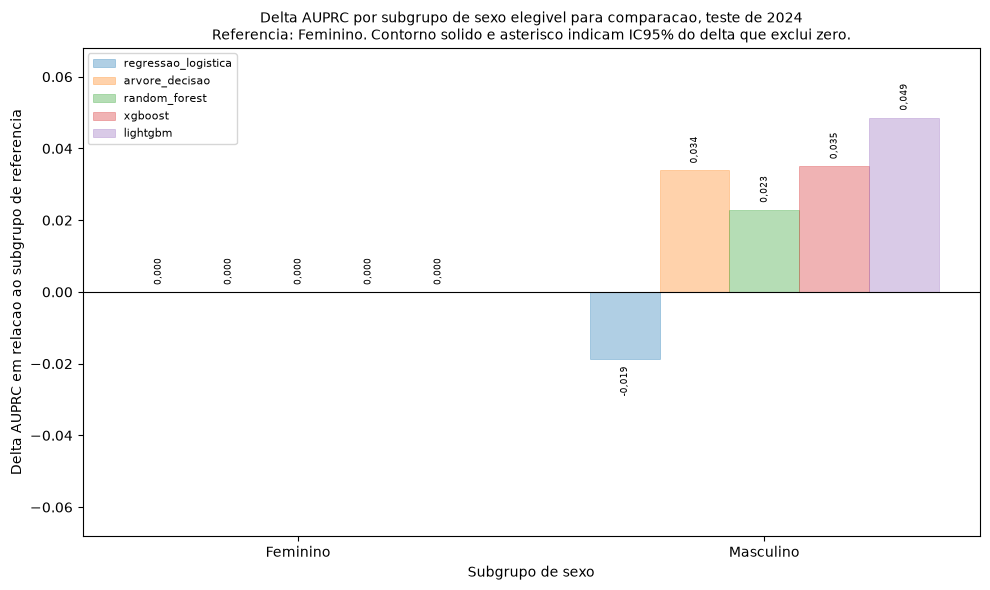

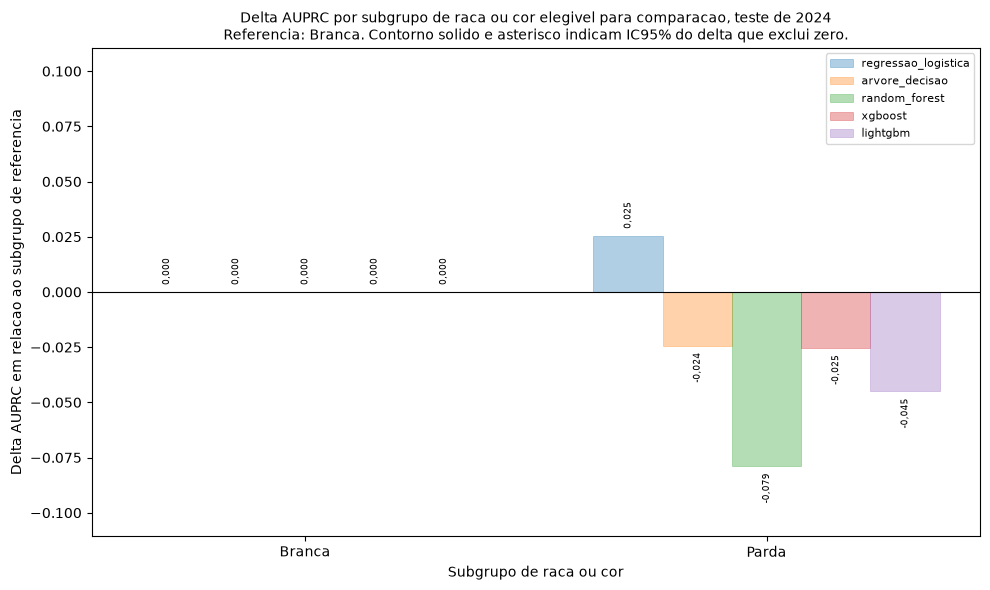

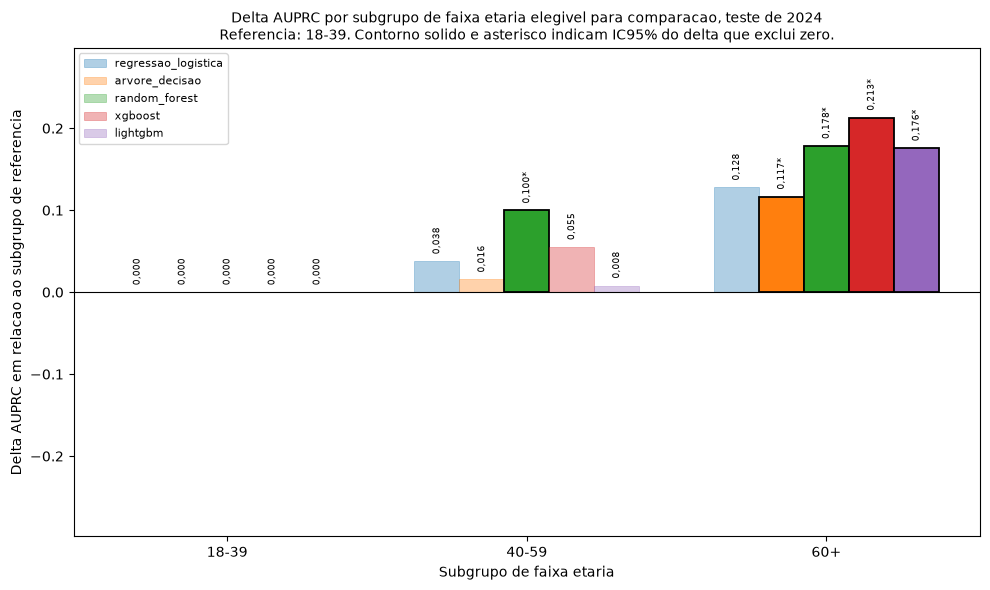

In [16]:
CORES_ALGORITMO = {
    "regressao_logistica": "tab:blue",
    "arvore_decisao": "tab:orange",
    "random_forest": "tab:green",
    "xgboost": "tab:red",
    "lightgbm": "tab:purple",
}

for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    rotulo_variavel = especificacao["rotulo_variavel"]
    rotulo_referencia = especificacao["rotulos_subgrupo"][especificacao["subgrupo_referencia"]]

    tabela_variavel = tabela_equidade_consolidada.loc[
        tabela_equidade_consolidada["variavel_estratificacao"] == nome_variavel
    ]
    tabela_variavel_elegivel = tabela_variavel.loc[tabela_variavel["elegivel_comparacao"]].copy()
    tabela_variavel_elegivel["delta_auprc"] = tabela_variavel_elegivel["delta_auprc"].astype(float)

    ordem_subgrupos = [
        especificacao["rotulos_subgrupo"][subgrupo] for subgrupo in especificacao["subgrupos"]
    ]
    subgrupos_elegiveis_ordenados = [
        rotulo for rotulo in ordem_subgrupos if rotulo in tabela_variavel_elegivel["subgrupo"].unique()
    ]

    matriz_delta_auprc = tabela_variavel_elegivel.pivot(
        index="subgrupo", columns="algoritmo", values="delta_auprc"
    ).loc[subgrupos_elegiveis_ordenados, ALGORITMOS]
    matriz_significancia_auprc = tabela_variavel_elegivel.pivot(
        index="subgrupo", columns="algoritmo", values="delta_auprc_significancia"
    ).loc[subgrupos_elegiveis_ordenados, ALGORITMOS]

    posicoes_subgrupo = np.arange(len(subgrupos_elegiveis_ordenados))
    largura_barra = 0.15
    maior_delta_absoluto = float(np.nanmax(np.abs(matriz_delta_auprc.to_numpy(dtype=float))))

    figura, eixo = plt.subplots(figsize=(10, 6))
    for indice_algoritmo, algoritmo in enumerate(ALGORITMOS):
        deslocamento = (indice_algoritmo - (len(ALGORITMOS) - 1) / 2) * largura_barra
        valores_delta = matriz_delta_auprc[algoritmo]
        significancias = matriz_significancia_auprc[algoritmo]
        cor_algoritmo = CORES_ALGORITMO[algoritmo]

        barras = eixo.bar(
            posicoes_subgrupo + deslocamento,
            valores_delta,
            width=largura_barra,
            label=algoritmo,
            color=cor_algoritmo,
        )

        for barra, significancia, valor_delta in zip(barras, significancias, valores_delta):
            eh_significativo = significancia == "significativo"
            barra.set_alpha(1.0 if eh_significativo else 0.35)
            barra.set_edgecolor("black" if eh_significativo else cor_algoritmo)
            barra.set_linewidth(1.3 if eh_significativo else 0.6)

            simbolo_significancia = "*" if eh_significativo else ""
            rotulo_valor = f"{valor_delta:.3f}{simbolo_significancia}".replace(".", ",")
            deslocamento_vertical = maior_delta_absoluto * 0.04
            posicao_vertical = valor_delta + deslocamento_vertical if valor_delta >= 0 else valor_delta - deslocamento_vertical
            alinhamento_vertical = "bottom" if valor_delta >= 0 else "top"
            eixo.text(
                barra.get_x() + barra.get_width() / 2,
                posicao_vertical,
                rotulo_valor,
                ha="center",
                va=alinhamento_vertical,
                fontsize=6.5,
                rotation=90,
            )

    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.set_xticks(posicoes_subgrupo)
    eixo.set_xticklabels(subgrupos_elegiveis_ordenados)
    eixo.set_ylim(-maior_delta_absoluto * 1.4, maior_delta_absoluto * 1.4)
    eixo.set_xlabel(f"Subgrupo de {rotulo_variavel}")
    eixo.set_ylabel("Delta AUPRC em relacao ao subgrupo de referencia")
    eixo.set_title(
        f"Delta AUPRC por subgrupo de {rotulo_variavel} elegivel para comparacao, teste de 2024\n"
        f"Referencia: {rotulo_referencia}. Contorno solido e asterisco indicam IC95% do delta que exclui zero.",
        fontsize=10,
    )
    eixo.legend(loc="best", fontsize=8)
    figura.tight_layout()
    figura.savefig(DIRETORIO_PLOTS / f"delta_auprc_{nome_variavel}.png", dpi=150)
    plt.show()

Para facilitar a leitura direta dos achados que sobrevivem ao bootstrap, esta celula reorganiza a tabela estendida em formato longo, uma linha por combinacao de variavel, subgrupo, algoritmo e metrica, mantendo apenas as combinacoes marcadas como significativas.
A coluna `elegivel_comparacao` e mantida em cada linha, para distinguir achados significativos entre subgrupos que tambem atendem ao criterio de estabilidade estatistica baseado na largura do intervalo de confianca de ROC-AUC dos achados significativos que, apesar de terem intervalo de confianca de delta fora de zero, vem de um subgrupo cuja propria estimativa de ROC-AUC e instavel.
O resultado e salvo em `analysis/results_equidade/deltas_significativos_bootstrap.csv`, e pode ficar vazio, com apenas o cabecalho das colunas, caso nenhum delta seja estatisticamente distinguivel de zero.

In [17]:
linhas_deltas_significativos = []
for _, linha in tabela_equidade_consolidada.iterrows():
    for nome_metrica, prefixo_coluna in [("auprc", "delta_auprc"), ("roc_auc", "delta_roc_auc")]:
        if linha[f"{prefixo_coluna}_significancia"] != "significativo":
            continue
        linhas_deltas_significativos.append(
            {
                "variavel_estratificacao": linha["variavel_estratificacao"],
                "subgrupo": linha["subgrupo"],
                "algoritmo": linha["algoritmo"],
                "metrica": nome_metrica,
                "delta_pontual": linha[prefixo_coluna],
                "ic95_inferior": linha[f"{prefixo_coluna}_ic95_inferior"],
                "ic95_superior": linha[f"{prefixo_coluna}_ic95_superior"],
                "fracao_reamostragens_positivo": linha[f"{prefixo_coluna}_fracao_reamostragens_positivo"],
                "elegivel_comparacao": linha["elegivel_comparacao"],
            }
        )

colunas_deltas_significativos = [
    "variavel_estratificacao",
    "subgrupo",
    "algoritmo",
    "metrica",
    "delta_pontual",
    "ic95_inferior",
    "ic95_superior",
    "fracao_reamostragens_positivo",
    "elegivel_comparacao",
]
tabela_deltas_significativos = pd.DataFrame(linhas_deltas_significativos, columns=colunas_deltas_significativos)
tabela_deltas_significativos = tabela_deltas_significativos.sort_values(
    ["variavel_estratificacao", "subgrupo", "algoritmo", "metrica"]
).reset_index(drop=True)

tabela_deltas_significativos.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "deltas_significativos_bootstrap.csv", index=False
)

tabela_deltas_significativos

,variavel_estratificacao,subgrupo,algoritmo,metrica,delta_pontual,ic95_inferior,ic95_superior,fracao_reamostragens_positivo,elegivel_comparacao
0,faixa_etaria,1-17,lightgbm,auprc,-0.038869,-0.112038,-0.003603,0.017553,False
1,faixa_etaria,1-17,random_forest,auprc,-0.035873,-0.088751,-0.010523,0.002002,False
2,faixa_etaria,1-17,regressao_logistica,auprc,-0.097716,-0.284457,-0.017939,0.006520,False
3,faixa_etaria,1-17,xgboost,auprc,-0.024467,-0.065799,-0.003005,0.015516,False
4,faixa_etaria,40-59,random_forest,auprc,0.099668,0.019144,0.218504,0.990500,True
5,faixa_etaria,60+,arvore_decisao,auprc,0.116667,0.085071,0.150843,1.000000,True
6,faixa_etaria,60+,lightgbm,auprc,0.175661,0.093643,0.244807,1.000000,True
7,faixa_etaria,60+,random_forest,auprc,0.178393,0.112018,0.238286,1.000000,True
8,faixa_etaria,60+,xgboost,auprc,0.212919,0.145147,0.285530,1.000000,True
9,faixa_etaria,<1,xgboost,roc_auc,0.231712,0.028955,0.430491,0.985398,False


## Sintese dos achados

As secoes anteriores substituiram o antigo limiar fixo de 10 obitos por um criterio de elegibilidade baseado na largura do intervalo de confianca de 95 por cento da ROC-AUC de cada subgrupo, exigida abaixo de 0,35 nos cinco algoritmos ao mesmo tempo.
Com esse criterio, sete subgrupos sao elegiveis para a comparacao de disparidade, Feminino e Masculino em sexo, Branca e Parda em raca ou cor, e 18 a 39 anos, 40 a 59 anos e 60 anos ou mais em faixa etaria, exatamente o mesmo conjunto que o limiar antigo de obitos produzia.
Os seis subgrupos antes excluidos por terem menos de 10 obitos, menor que 1 ano, 1 a 17 anos, Amarela, Ignorado, Indigena e Preta, continuam todos nao elegiveis, agora por terem largura maxima de intervalo de confianca de ROC-AUC entre 0,52 e 0,72, ou por nao terem ROC-AUC definida no caso de Indigena, que reune zero obitos.
A diferenca central em relacao a versao anterior desta analise e que esses seis subgrupos deixam de ser omitidos sem numero algum, e passam a ter delta de AUPRC e de ROC-AUC calculado pelo mesmo bootstrap de duas amostras independentes usado nos subgrupos elegiveis, com a devida marcacao de que nao entram na comparacao de disparidade.

Entre os subgrupos elegiveis, o conjunto de achados estatisticamente significativos tambem nao muda em relacao a versao anterior desta analise.
Das quinze comparacoes elegiveis possiveis, cinco subgrupos nao referencia em tres variaveis, vezes cinco algoritmos, vezes duas metricas, apenas cinco tem intervalo de confianca de 95 por cento que nao contem zero, e as cinco sao deltas de AUPRC da faixa etaria.
Nenhum delta de sexo, nenhum delta de raca ou cor, e nenhum delta de ROC-AUC de qualquer variavel elegivel sobrevive ao bootstrap como estatisticamente distinguivel de zero.

Para sexo, o subgrupo Masculino tem AUPRC pontual mais alta do que o Feminino em quatro dos cinco algoritmos, mas o intervalo de confianca do delta AUPRC inclui zero nos cinco algoritmos.
O delta ROC-AUC de sexo e negativo nos cinco algoritmos na estimativa pontual, e tambem tem intervalo de confianca que inclui zero nos cinco casos, embora a fracao de reamostragens com delta negativo chegue a 90,8 por cento na Arvore de Decisao e no Random Forest, o indicio de direcao mais consistente encontrado nesta variavel que, ainda assim, nao cruza o limiar de significancia de 95 por cento.

Para raca ou cor, a unica comparacao elegivel continua sendo Parda contra Branca, e nenhum dos dez deltas, cinco de AUPRC e cinco de ROC-AUC, tem intervalo de confianca fora de zero.
O caso mais proximo do limiar de significancia e o delta AUPRC do Random Forest, com intervalo de confianca entre -0,191 e 0,014 e apenas 4,5 por cento das reamostragens com delta positivo, o que aponta na mesma direcao da estimativa pontual sem excluir a hipotese de delta zero.
Fora da comparacao elegivel, a categoria Ignorado chama atencao por ter delta de AUPRC significativamente negativo em relacao a Branca nos cinco algoritmos, e delta de ROC-AUC significativamente negativo na Arvore de Decisao, um padrao consistente que a largura de intervalo de confianca de 0,54 da propria ROC-AUC de Ignorado impede de tratar como uma medida confiavel de disparidade racial, e que de qualquer forma nao deveria ser lido como equidade entre racas, porque ignorado nao e uma categoria racial.
A categoria Amarela tambem mostra um delta de AUPRC e um delta de ROC-AUC significativamente negativos, mas apenas no XGBoost, isolado nos outros quatro algoritmos, com largura de intervalo de confianca da propria ROC-AUC de 0,72, a maior de toda a tabela entre os subgrupos com metrica definida.

Faixa etaria e a unica variavel elegivel com deltas que sobrevivem ao bootstrap, e apenas para AUPRC, nunca para ROC-AUC.
O delta AUPRC da faixa de 60 anos ou mais em relacao a de 18 a 39 anos tem intervalo de confianca inteiramente positivo em quatro dos cinco algoritmos, Arvore de Decisao, Random Forest, XGBoost e LightGBM, com 100 por cento das reamostragens positivas nos quatro.
Na Regressao Logistica, o unico dos cinco algoritmos em que esse delta nao e significativo, a estimativa pontual fica dentro da faixa dos outros quatro algoritmos, mas o intervalo de confianca e varias vezes mais largo, o que reflete maior variancia da AUPRC sob reamostragem nesse algoritmo especificamente, e nao uma estimativa pontual discrepante.
O delta AUPRC da faixa de 40 a 59 anos em relacao a de 18 a 39 anos e significativo apenas no Random Forest, com 99,1 por cento das reamostragens positivas, enquanto o XGBoost chega perto do limiar, com 96,7 por cento das reamostragens positivas, sem o limite inferior cruzar para o lado positivo.
Para nenhuma das duas faixas, 40 a 59 ou 60 anos ou mais, o delta ROC-AUC tem intervalo de confianca fora de zero em qualquer dos cinco algoritmos.
Fora da comparacao elegivel, a faixa de 1 a 17 anos mostra delta de AUPRC significativamente negativo em relacao a 18 a 39 anos em quatro dos cinco algoritmos, e a faixa menor que 1 ano mostra delta de ROC-AUC significativamente positivo no XGBoost isoladamente, dois achados que a largura de intervalo de confianca da propria ROC-AUC desses dois subgrupos, acima de 0,52, impede de tratar como estimativas confiaveis de disparidade por idade.

Em conjunto, o criterio de elegibilidade baseado na largura do intervalo de confianca de ROC-AUC chega, para os subgrupos grandes o suficiente para sustentar a comparacao, exatamente as mesmas conclusoes substantivas da versao anterior desta analise, que usava um limiar fixo de 10 obitos.
A capacidade de discriminacao de risco, medida pelo ROC-AUC, nao tem nenhuma diferenca estatisticamente distinguivel de zero entre subgrupos elegiveis em nenhuma das tres variaveis de estratificacao, com os dados e os modelos atuais.
O unico achado que sobrevive entre os subgrupos elegiveis e uma AUPRC mais alta no subgrupo de 60 anos ou mais do que no de 18 a 39 anos, presente em quatro dos cinco algoritmos, compativel com a maior prevalencia observada de obito nessa faixa etaria, ja que a AUPRC tem a prevalencia da classe positiva como piso.
A vantagem da nova analise nao esta na conclusao principal, que se mantem, mas na transparencia, porque os seis subgrupos antes tratados apenas como amostra insuficiente agora tem numero, intervalo de confianca e, em alguns casos, um sinal de diferenca que a largura da propria ROC-AUC avisa explicitamente para nao superinterpretar, em vez de permanecerem invisiveis na analise.
Essa conclusao reforca a necessidade de reportar, ao lado de qualquer delta de equidade, tanto o intervalo de confianca do delta quanto a largura do intervalo de confianca da metrica do proprio subgrupo, em vez de decidir a inclusao de um subgrupo por um numero de eventos escolhido sem relacao com o comportamento estatistico observado.